# Specific gravity and Brix

In [1]:
from pathlib import Path
import os
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "03_brix":
    ROOT = ROOT.parent.parent
if not (ROOT / "batches").is_dir():
    raise FileNotFoundError("Open this notebook from the project folder.")
BATCH_DIR = ROOT / "batches/03_brix"
os.chdir(BATCH_DIR)
%matplotlib inline

## Conversion functions

Specific-gravity conversion uses the polynomial from the existing workbook analysis.

In [2]:
from pathlib import Path

import re

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

workbook = ROOT / "data/processed/Harvest 2026 Sapkota lab CLEANED.xlsx"

figures = Path("figures")

figures.mkdir(exist_ok=True)

UK_BLUE = "#0033A0"

def sg_to_brix(sg: float) -> float:
    return (
        143.254 * (sg**3)
        - 648.67 * (sg**2)
        + 1125.805 * sg
        - 620.389
    )

def soluble_solids_class(brix):
    """Interpretive TSS bins for fresh tomato (not a sweetness grade)."""
    if pd.isna(brix):
        return pd.NA
    b = float(brix)
    if b < 5.0:
        return "<5.0 lower TSS"
    if b < 6.5:
        return "5.0–6.5 typical TSS"
    if b < 8.0:
        return "6.5–8.0 high TSS"
    return "≥8.0 very high TSS"

def flavor_band(brix):
    """Map °Brix onto the lab 'Brix scale' note (Jon Rowley tomato challenge).

    Gaps between published bands are assigned to the nearest lower band so every
    assay gets one label. This is a flavor-context aid, not a sensory grade.
    """
    if pd.isna(brix):
        return pd.NA
    b = float(brix)
    if b < 5.0:
        return "3.0–4.5 commercial / lower"
    if b < 6.0:
        return "5.0–5.5 average fresh-market"
    if b < 8.0:
        return "6.0–7.0 good garden flavor"
    if b < 10.0:
        return "8.0–9.5 specialty / cherry-sweet"
    if b < 14.0:
        return "10.0–12.0 exceptionally rich"
    return "14.0+ contest-worthy"

## Lab measurements

Headers are in row 2 of Lab_Specific_Gravity.

In [3]:
BRIX_SCALE_PATH = Path("brix_scale.txt")

brix_scale_rows = []

brix_scale_source = ""

if BRIX_SCALE_PATH.exists():
    for line in BRIX_SCALE_PATH.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line:
            continue
        if line.startswith("http"):
            brix_scale_source = line
            continue
        if ":" in line:
            band, meaning = line.split(":", 1)
            brix_scale_rows.append(
                {"°Brix band": band.strip(), "Flavor context": meaning.strip()}
            )

raw = pd.read_excel(workbook, sheet_name="Lab_Specific_Gravity", header=1)

raw = raw.dropna(how="all").copy()

raw.columns = [str(c).strip() if pd.notna(c) else c for c in raw.columns]

rename = {}

for col in raw.columns:
    low = str(col).strip().lower()
    if low == "reading 1":
        rename[col] = "Reading 1"
    elif low == "reading 2":
        rename[col] = "Reading 2"
    elif low == "reading 3":
        rename[col] = "Reading 3"
    elif low == "average":
        rename[col] = "Average"
    elif low == "brix":
        rename[col] = "Brix"

raw = raw.rename(columns=rename)

master = raw.copy()

master["Genotype_raw"] = master["Genotypes"]

for column in ["Genotypes", "Location", "Harvest"]:
    if column in master.columns:
        master[column] = master[column].astype("string").str.strip()

for column in ["Reading 1", "Reading 2", "Reading 3", "Average", "Brix"]:
    master[column] = pd.to_numeric(master[column], errors="coerce")

master["Date of harvest"] = pd.to_datetime(
    master["Date of harvest"], errors="coerce"
)

## Location and genotype labels

In [4]:
master["Location"] = (
    master["Location"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

master["Location"] = master["Location"].replace(
    {
        r"(?i)^high\s*tunnel$": "High tunnel",
        r"(?i)^hightunnel$": "High tunnel",
        r"(?i)^open\s*field$": "South Farm",
        r"(?i)^south\s*farm$": "South Farm",
        r"(?i)^southfarm$": "South Farm",
        r"(?i)^robinson$": "Robinson",
        r"(?i)^robinson\s*center$": "Robinson",
    },
    regex=True,
)

master["Harvest"] = (
    master["Harvest"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)

master["Harvest"] = master["Harvest"].replace(
    {
        r"(?i)^first$": "first",
        r"(?i)^second$": "second",
        r"(?i)^third$": "third",
    },
    regex=True,
)

COMMERCIAL_ALIASES = {
    "mt. fresh": "Mountain Fresh",
    "mt fresh": "Mountain Fresh",
    "mountain fresh": "Mountain Fresh",
    "mt. fresh plus": "Mt. Fresh Plus",
    "mt fresh plus": "Mt. Fresh Plus",
    "mt. gem": "Mt. Gem",
    "mt gem": "Mt. Gem",
    "mt. girl": "Mt. Girl",
    "mt girl": "Mt. Girl",
    "mt. heritage": "Mt. Heritage",
    "mt heritage": "Mt. Heritage",
    "mt. magic": "Mt. Magic",
    "mt magic": "Mt. Magic",
    "cherokee purple": "Cherokee Purple",
    "maglia r cherry": "Maglia Rosa Cherry",
    "maglia rosa ch": "Maglia Rosa Cherry",
    "maglia rosa cherry": "Maglia Rosa Cherry",
    "peace vine": "Peace Vine",
    "peachvine ch.": "Peace Vine",
    "peachvine ch": "Peace Vine",
}

def extract_replicate(name):
    """Return (base_name, replicate_or_NA) for trailing R1 / R2 / R3 tags."""
    if pd.isna(name):
        return name, pd.NA
    text = str(name).strip()
    m = re.search(r"\s+R(\d+)\s*$", text, flags=re.I)
    if m:
        return text[: m.start()].strip(), f"R{m.group(1)}"
    return text, pd.NA

In [5]:
def clean_genotype(name):
    """Normalize UKYT lines and light commercial aliases; collapse NC spaces."""
    if pd.isna(name):
        return name
    text = str(name).strip()
    text = re.sub(r"\s+", " ", text)
    # Trailing period typos like 26-013.
    text = text.rstrip(".")

    uk_short = re.match(r"^(\d{2})-(\d{1,3})$", text)
    if uk_short:
        year, number = uk_short.group(1), int(uk_short.group(2))
        return f"UKYT-{year}-{number:03d}"

    uk_line = re.match(
        r"(?i)^uky[t]?\s*-?\s*(\d{2})\s*-?\s*(\d{1,3})$",
        text,
    )
    if uk_line:
        year, number = uk_line.group(1), int(uk_line.group(2))
        return f"UKYT-{year}-{number:03d}"

    key = text.lower()
    if key in COMMERCIAL_ALIASES:
        return COMMERCIAL_ALIASES[key]

    # Collapse spaces inside NC / NG accession-like codes: "NC 25203G" → "NC25203G"
    nc = re.match(r"(?i)^(n[cg])\s*(\d[\d\s]*[a-z]?)$", text)
    if nc:
        prefix = nc.group(1).upper()
        rest = re.sub(r"\s+", "", nc.group(2)).upper()
        return f"{prefix}{rest}"

    # Bare numeric-ish codes with spaces: "264 G" → "264G", "25241 G" → "25241G"
    bare = re.match(r"^(\d+)\s+([A-Za-z])$", text)
    if bare:
        return f"{bare.group(1)}{bare.group(2).upper()}"

    return text

bases = []

reps = []

for raw_name in master["Genotype_raw"]:
    base, rep = extract_replicate(raw_name)
    bases.append(base)
    reps.append(rep)

master["Replicate"] = pd.Series(reps, dtype="string")

master["Genotypes"] = pd.Series(bases, dtype="string").map(clean_genotype)

## Reading correction

NC25218G Reading 2 is changed from 1.22 to 1.022. The entered value remains in Reading_2_raw. Check the correction against the original lab record.

In [6]:
master["QC_flag"] = pd.Series(pd.NA, dtype="string")

master["Reading_2_raw"] = master["Reading 2"]

typo_mask = (
    (master["Genotype_raw"].astype(str).str.replace(r"\s+", "", regex=True)
     .str.upper() == "NC25218G")
    & (master["Reading 2"] > 1.1)
)

master.loc[typo_mask, "Reading 2"] = 1.022

master.loc[typo_mask, "QC_flag"] = "corrected_Reading2_1.22_to_1.022"

reading_cols = ["Reading 1", "Reading 2", "Reading 3"]

master["Average"] = master[reading_cols].mean(axis=1, skipna=True)

master["Brix"] = master["Average"].map(
    lambda x: sg_to_brix(float(x)) if pd.notna(x) else np.nan
)

master["Reading_range"] = master[reading_cols].max(axis=1) - master[
    reading_cols
].min(axis=1)

master["Reading_sd"] = master[reading_cols].std(axis=1, ddof=1)

master["TSS_class"] = master["Brix"].map(soluble_solids_class)

high_range = (master["Reading_range"] >= 0.010) & master["QC_flag"].isna()

master.loc[high_range, "QC_flag"] = "high_reading_range"

column_order = [
    "SN",
    "Genotype_raw",
    "Genotypes",
    "Replicate",
    "Location",
    "Date of harvest",
    "Harvest",
    "Reading 1",
    "Reading 2",
    "Reading 3",
    "Average",
    "Brix",
    "TSS_class",
    "Reading_range",
    "Reading_sd",
    "QC_flag",
    "Reading_2_raw",
]

column_order = [c for c in column_order if c in master.columns]

master = master[column_order]

master.to_csv("sg_brix_master.csv", index=False)

changed = master[master["Genotype_raw"].astype(str) != master["Genotypes"].astype(str)][
    ["Genotype_raw", "Genotypes"]
].drop_duplicates()

## Genotype and site summaries

In [7]:
by_geno = master.groupby("Genotypes", dropna=False)

loc_counts = (
    master.assign(
        _ht=(master["Location"] == "High tunnel").fillna(False).astype(int),
        _sf=(master["Location"] == "South Farm").fillna(False).astype(int),
        _rob=(master["Location"] == "Robinson").fillna(False).astype(int),
    )
    .groupby("Genotypes", dropna=False)[["_ht", "_sf", "_rob"]]
    .sum()
    .rename(
        columns={
            "_ht": "n_high_tunnel",
            "_sf": "n_south_farm",
            "_rob": "n_robinson",
        }
    )
)

geno_summary = pd.DataFrame(
    {
        "n": by_geno.size(),
        "mean_brix": by_geno["Brix"].mean(),
        "median_brix": by_geno["Brix"].median(),
        "min_brix": by_geno["Brix"].min(),
        "max_brix": by_geno["Brix"].max(),
        "sd_brix": by_geno["Brix"].std(ddof=1),
        "mean_sg": by_geno["Average"].mean(),
        "n_locations": by_geno["Location"].nunique(dropna=True),
    }
).join(loc_counts)

geno_summary = geno_summary.reset_index()

geno_summary = geno_summary.sort_values(
    ["mean_brix", "Genotypes"], ascending=[False, True], na_position="last"
)

geno_summary["rank_by_mean_brix"] = range(1, len(geno_summary) + 1)

geno_summary["TSS_class"] = geno_summary["mean_brix"].map(soluble_solids_class)

geno_summary = geno_summary[
    [
        "rank_by_mean_brix",
        "Genotypes",
        "n",
        "mean_brix",
        "median_brix",
        "min_brix",
        "max_brix",
        "sd_brix",
        "mean_sg",
        "TSS_class",
        "n_high_tunnel",
        "n_south_farm",
        "n_robinson",
        "n_locations",
    ]
]

geno_summary.to_csv("genotype_brix_summary.csv", index=False)

loc_summary = (
    master.dropna(subset=["Location"])
    .groupby(["Genotypes", "Location"], dropna=False)
    .agg(
        n=("Brix", "size"),
        mean_brix=("Brix", "mean"),
        median_brix=("Brix", "median"),
        min_brix=("Brix", "min"),
        max_brix=("Brix", "max"),
        sd_brix=("Brix", "std"),
        mean_sg=("Average", "mean"),
    )
    .reset_index()
    .sort_values(["Location", "mean_brix", "Genotypes"], ascending=[True, False, True])
)

loc_summary.to_csv("genotype_location_brix.csv", index=False)

## Rankings and yield join

In [8]:
top15_overall = geno_summary.head(15).copy()

top15_overall.to_csv("top15_brix_overall.csv", index=False)

LOCATION_ORDER = ["High tunnel", "South Farm", "Robinson"]

top15_by_location = {}

for loc in LOCATION_ORDER:
    sub = loc_summary[loc_summary["Location"] == loc].copy()
    sub = sub.sort_values(["mean_brix", "Genotypes"], ascending=[False, True])
    rank_col = f"rank_by_mean_brix_{loc.lower().replace(' ', '_')}"
    sub[rank_col] = range(1, len(sub) + 1)
    sub["TSS_class"] = sub["mean_brix"].map(soluble_solids_class)
    top = sub.head(15)[
        [
            rank_col,
            "Genotypes",
            "n",
            "mean_brix",
            "median_brix",
            "min_brix",
            "max_brix",
            "sd_brix",
            "mean_sg",
            "TSS_class",
        ]
    ].copy()
    top15_by_location[loc] = top
    slug = loc.lower().replace(" ", "_")
    out_path = f"top15_brix_{slug}.csv"
    top.to_csv(out_path, index=False)
    print(f"Saved {out_path}")

top15_ht = top15_by_location["High tunnel"]

top15_sf = top15_by_location["South Farm"]

top15_rob = top15_by_location["Robinson"]

top15_n2 = geno_summary[geno_summary["n"] >= 2].head(15).copy()

top15_n2.to_csv("top15_brix_overall_n_ge2.csv", index=False)

yield_path = ROOT / "batches/02_high_tunnel/genotype_summary.csv"

Saved top15_brix_high_tunnel.csv
Saved top15_brix_south_farm.csv
Saved top15_brix_robinson.csv


In [9]:
if yield_path.exists():
    yield_df = pd.read_csv(yield_path)
    ht_means = (
        loc_summary[loc_summary["Location"] == "High tunnel"][
            ["Genotypes", "n", "mean_brix"]
        ].rename(columns={"n": "n_brix_ht", "mean_brix": "mean_brix_ht"})
    )
    overall_means = geno_summary[
        ["Genotypes", "n", "mean_brix", "n_high_tunnel", "n_south_farm", "n_robinson"]
    ].rename(columns={"n": "n_brix_all", "mean_brix": "mean_brix_all"})

    join = yield_df.merge(overall_means, on="Genotypes", how="left")
    join = join.merge(ht_means, on="Genotypes", how="left")
    join_cols = [
        "rank_by_total_weight",
        "rank_by_mean_per_harvest",
        "Genotypes",
        "n_harvests_with_weight",
        "total_marketable_weight",
        "total_weight",
        "mean_weight_per_harvest",
        "marketable_percentage",
        "n_brix_all",
        "mean_brix_all",
        "n_brix_ht",
        "mean_brix_ht",
        "n_high_tunnel",
        "n_south_farm",
        "n_robinson",
    ]
    join = join[[c for c in join_cols if c in join.columns]]
    join.to_csv("ht_yield_brix_join.csv", index=False)
    print("Saved ht_yield_brix_join.csv")
    print(
        f"Yield genotypes with any Brix: "
        f"{join['mean_brix_all'].notna().sum()} / {len(join)}"
    )
    print(
        f"Yield genotypes with HT Brix: "
        f"{join['mean_brix_ht'].notna().sum()} / {len(join)}"
    )
else:
    join = pd.DataFrame()
    print("WARNING: genotype_summary.csv missing; skip yield–Brix join")

Saved ht_yield_brix_join.csv
Yield genotypes with any Brix: 46 / 50
Yield genotypes with HT Brix: 25 / 50


## Site summaries

In [10]:
loc_overall = (
    master.dropna(subset=["Location"])
    .groupby("Location")
    .agg(
        n=("Brix", "size"),
        mean_brix=("Brix", "mean"),
        median_brix=("Brix", "median"),
        min_brix=("Brix", "min"),
        max_brix=("Brix", "max"),
        sd_brix=("Brix", "std"),
    )
    .reset_index()
    .sort_values("Location")
)

harvest_loc = (
    master.dropna(subset=["Location", "Harvest"])
    .groupby(["Location", "Harvest"])
    .agg(n=("Brix", "size"), mean_brix=("Brix", "mean"))
    .reset_index()
)

## Brix plots

In [11]:
def plot_top_bars(df, value_col, geno_col, path, title, xlabel):
    plot_df = df.sort_values(value_col, ascending=True)
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    vals = plot_df[value_col]
    ax.barh(plot_df[geno_col], vals, color=UK_BLUE)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for y, v in enumerate(vals):
        ax.text(v + 0.05, y, f"{v:.2f}", va="center", fontsize=8, color="#4a4a4a")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5.5))

loc_order = LOCATION_ORDER

plot_data = master[master["Location"].isin(loc_order)].copy()

positions = list(range(len(loc_order)))

box_data = [
    plot_data.loc[plot_data["Location"] == loc, "Brix"].dropna().values
    for loc in loc_order
]

bp = ax.boxplot(
    box_data,
    positions=positions,
    widths=0.45,
    patch_artist=True,
    showfliers=False,
)

for patch in bp["boxes"]:
    patch.set_facecolor("#D6E2F5")
    patch.set_edgecolor(UK_BLUE)

for median in bp["medians"]:
    median.set_color(UK_BLUE)
    median.set_linewidth(1.5)

rng = np.random.default_rng(42)

for i, loc in enumerate(loc_order):
    vals = plot_data.loc[plot_data["Location"] == loc, "Brix"].dropna().values
    jitter = rng.uniform(-0.12, 0.12, size=len(vals))
    ax.scatter(
        np.full(len(vals), i) + jitter,
        vals,
        s=18,
        alpha=0.55,
        color=UK_BLUE,
        zorder=3,
        edgecolors="none",
    )

ax.set_xticks(positions)

ax.set_xticklabels(
    [f"{loc}\n(n={len(box_data[i])})" for i, loc in enumerate(loc_order)]
)

ax.set_ylabel("Brix")

ax.set_title("Brix by location")

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(figures / "fig_brix1_by_location.png", dpi=150)

plt.close(fig)

plot_top_bars(
    top15_overall,
    "mean_brix",
    "Genotypes",
    figures / "fig_brix2_top15_overall.png",
    "Top 15 by mean Brix, all locations",
    "Mean Brix",
)

plot_top_bars(
    top15_ht,
    "mean_brix",
    "Genotypes",
    figures / "fig_brix3_top15_high_tunnel.png",
    "Top 15 by mean Brix, High tunnel",
    "Mean Brix",
)

In [12]:
plot_top_bars(
    top15_sf,
    "mean_brix",
    "Genotypes",
    figures / "fig_brix3b_top15_south_farm.png",
    "Top 15 by mean Brix, South Farm",
    "Mean Brix",
)

plot_top_bars(
    top15_rob,
    "mean_brix",
    "Genotypes",
    figures / "fig_brix3c_top15_robinson.png",
    "Top 15 by mean Brix, Robinson",
    "Mean Brix",
)

plot_top_bars(
    top15_n2,
    "mean_brix",
    "Genotypes",
    figures / "fig_brix4_top15_overall_n_ge2.png",
    "Top 15 by mean Brix, n ≥ 2 rows",
    "Mean Brix",
)

## Yield and Brix

Only matching genotype IDs are included.

In [13]:
if not join.empty and join["mean_brix_ht"].notna().any():
    scatter = join.dropna(subset=["mean_brix_ht", "total_weight"]).copy()
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(
        scatter["mean_brix_ht"],
        scatter["total_weight"] / 1000,
        s=55,
        color=UK_BLUE,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.5,
    )
    for _, row in scatter.iterrows():
        ax.annotate(
            row["Genotypes"],
            (row["mean_brix_ht"], row["total_weight"] / 1000),
            textcoords="offset points",
            xytext=(4, 3),
            fontsize=7,
            color="#4a4a4a",
        )
    ax.set_xlabel("Mean Brix (high tunnel)")
    ax.set_ylabel("Total harvest weight (kg)")
    ax.set_title("High tunnel: yield vs mean Brix")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(figures / "fig_brix5_yield_vs_brix_ht.png", dpi=150)
    plt.close(fig)

    scatter2 = join.dropna(subset=["mean_brix_ht", "mean_weight_per_harvest"]).copy()
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(
        scatter2["mean_brix_ht"],
        scatter2["mean_weight_per_harvest"] / 1000,
        s=55,
        color=UK_BLUE,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.5,
    )
    for _, row in scatter2.iterrows():
        ax.annotate(
            row["Genotypes"],
            (row["mean_brix_ht"], row["mean_weight_per_harvest"] / 1000),
            textcoords="offset points",
            xytext=(4, 3),
            fontsize=7,
            color="#4a4a4a",
        )
    ax.set_xlabel("Mean Brix (high tunnel)")
    ax.set_ylabel("Mean weight per harvest (kg)")
    ax.set_title("High tunnel: mean yield/harvest vs mean Brix")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(figures / "fig_brix6_mean_yield_vs_brix_ht.png", dpi=150)
    plt.close(fig)

In [14]:
if not harvest_loc.empty:
    fig, ax = plt.subplots(figsize=(8.5, 5))
    harvest_order = ["first", "second", "third"]
    colors = {
        "High tunnel": UK_BLUE,
        "South Farm": "#5B8DEF",
        "Robinson": "#7A7A7A",
    }
    for loc in loc_order:
        sub = harvest_loc[harvest_loc["Location"] == loc]
        if sub.empty:
            continue
        xs, ys = [], []
        for h in harvest_order:
            row = sub[sub["Harvest"] == h]
            if not row.empty:
                xs.append(h)
                ys.append(float(row.iloc[0]["mean_brix"]))
        if xs:
            ax.plot(
                xs,
                ys,
                marker="o",
                linewidth=1.8,
                label=loc,
                color=colors.get(loc, UK_BLUE),
            )
    ax.set_ylabel("Mean Brix")
    ax.set_xlabel("Harvest")
    ax.set_title("Mean Brix by harvest and location")
    ax.legend(frameon=False, fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(figures / "fig_brix7_by_harvest_location.png", dpi=150)
    plt.close(fig)

## Summary table

In [15]:
review = pd.read_csv("genotype_location_brix.csv")
display(review[['Genotypes', 'Location', 'n', 'mean_brix', 'sd_brix']].head(10))
print("Exported rows:", len(review))

,Genotypes,Location,n,mean_brix,sd_brix
0,UKYT-25-016,High tunnel,1,8.775925,NaN
1,UKYT-25-008,High tunnel,4,7.445230,1.542662
2,UKYT-25-015,High tunnel,3,7.059670,0.985231
3,UKYT-25-005,High tunnel,3,6.840559,0.988121
4,UKYT-25-003,High tunnel,4,6.670034,0.724220
5,UKYT-26-006,High tunnel,3,6.649809,0.658659
6,UKYT-25-017,High tunnel,3,6.565417,1.155683
7,UKYT-25-011,High tunnel,4,6.278796,0.637458
8,UKYT-25-007,High tunnel,3,6.238000,0.495379
9,UKYT-25-014,High tunnel,3,6.209451,0.836721


Exported rows: 160


## Flagged readings

In [16]:
display(master.loc[master["QC_flag"].notna(), ["Genotype_raw", "Location", "Reading_2_raw", "Reading 2", "Brix", "QC_flag"]])

,Genotype_raw,Location,Reading_2_raw,Reading 2,Brix,QC_flag
85,UKYT-25-013,Robinson,1.040,1.040,8.613547,high_reading_range
217,UKYT-26-024,South Farm,1.035,1.035,7.717222,high_reading_range


## Figures

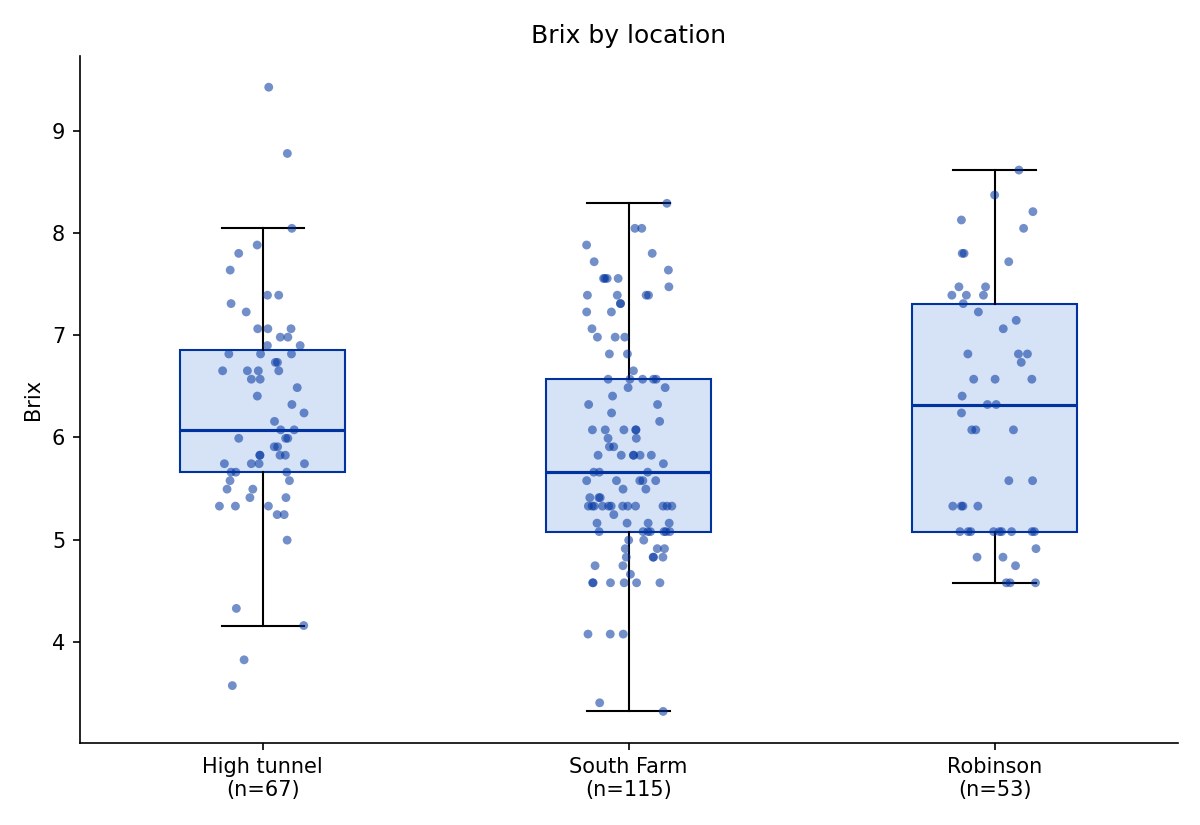

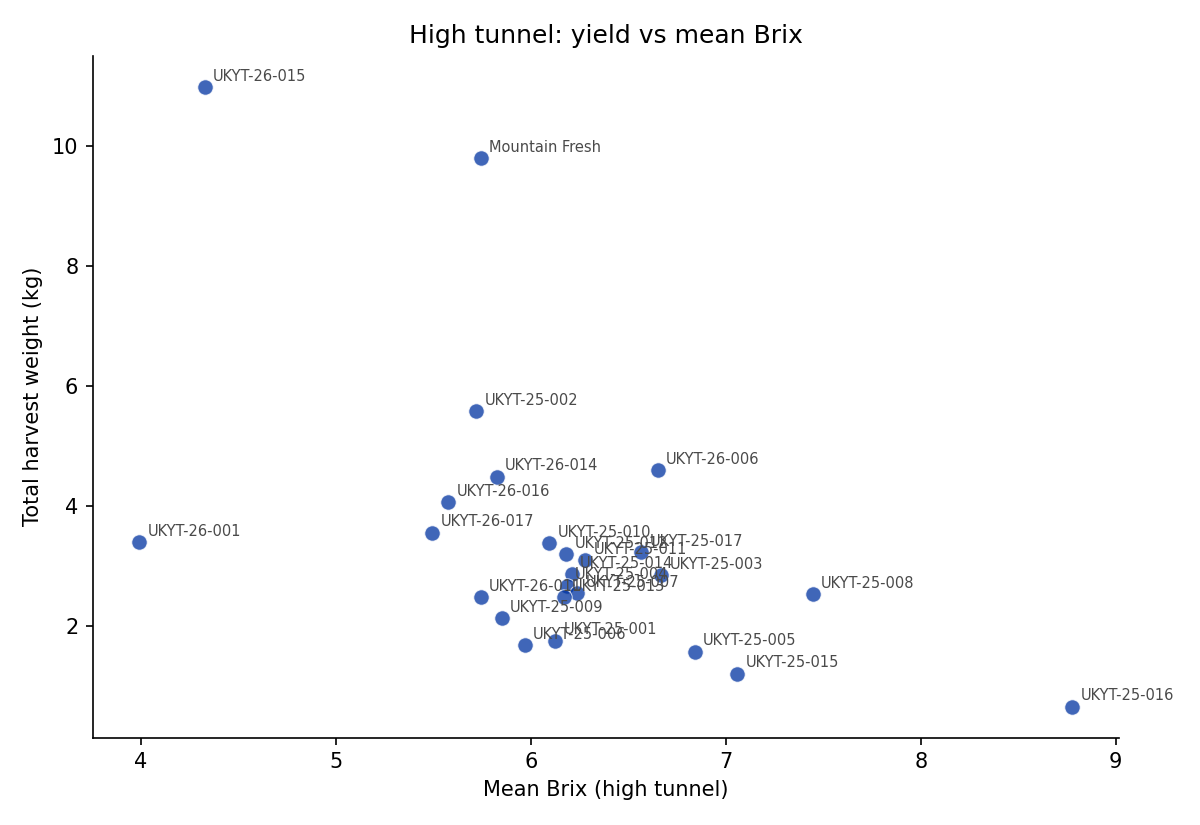

In [17]:
display(Image(filename="figures/fig_brix1_by_location.png"))
display(Image(filename="figures/fig_brix5_yield_vs_brix_ht.png"))